https://www.bps.go.id/id/statistics-table/2/MTc1NCMy/nilai-impor-migas-nonmigas--juta-us--.html

## Libraries

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from matplotlib import pyplot as plt
import tensorflow as tf
from sklearn.metrics import mean_absolute_error

## Data

In [ ]:
data = pd.read_excel("/content/Data LSTM Forecast Nilai Ekspor Nonmigas.xlsx")
data.head()

,Bulan,Nilai Ekspor Nonmigas
0,2005-01-01,3062.4
1,2005-02-01,3261.9
2,2005-03-01,3502.1
3,2005-04-01,3534.1
4,2005-05-01,3643.7


## Grafik Nilai Ekspor Nonmigas

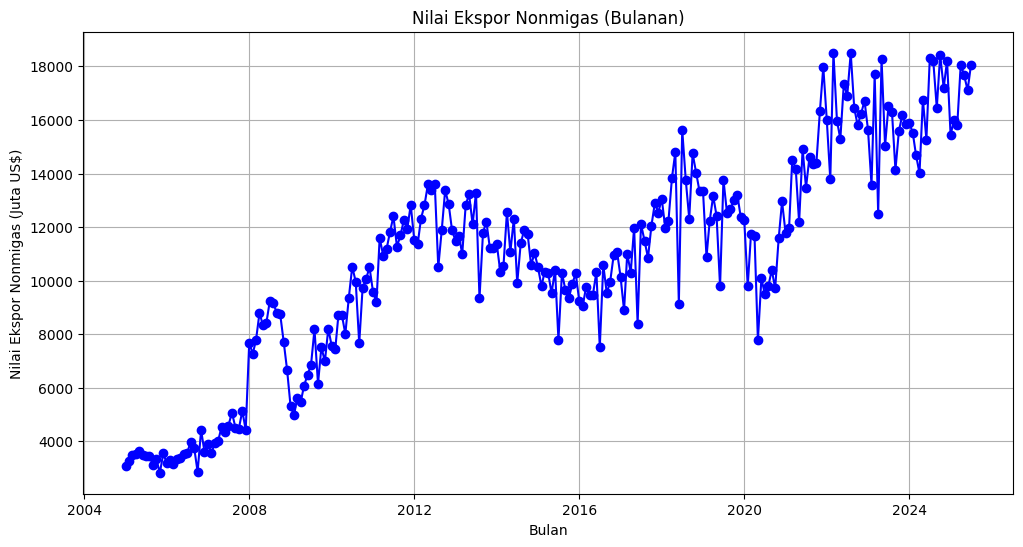

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(data['Bulan'], data['Nilai Ekspor Nonmigas'], color='blue', marker='o')
plt.title("Nilai Ekspor Nonmigas (Bulanan)")
plt.xlabel("Bulan")
plt.ylabel("Nilai Ekspor Nonmigas (Juta US$)")
plt.grid(True)
plt.show()

## Statistika Deskriptif

In [ ]:
data.describe()

,Bulan,Nilai Ekspor Nonmigas
count,247,247.000000
mean,2015-04-01 17:46:52.955465472,10758.408097
min,2005-01-01 00:00:00,2829.800000
25%,2010-02-15 00:00:00,8407.800000
50%,2015-04-01 00:00:00,11080.600000
75%,2020-05-16 12:00:00,13361.050000
max,2025-07-01 00:00:00,18509.100000
std,NaN,4076.208111


## Data Preparation

In [ ]:
df = pd.DataFrame(data)
print(df)

         Bulan  Nilai Ekspor Nonmigas
0   2005-01-01                 3062.4
1   2005-02-01                 3261.9
2   2005-03-01                 3502.1
3   2005-04-01                 3534.1
4   2005-05-01                 3643.7
..         ...                    ...
242 2025-03-01                15792.4
243 2025-04-01                18065.5
244 2025-05-01                17668.6
245 2025-06-01                17111.2
246 2025-07-01                18061.9

[247 rows x 2 columns]


In [ ]:
# memisahkan fitur input dan output
input_features = ['Nilai Ekspor Nonmigas']
output_features = ['Nilai Ekspor Nonmigas']

In [ ]:
X = df[input_features].values
y = df[output_features].values

In [ ]:
print(X)
print(y)

[[ 3062.4]
 [ 3261.9]
 [ 3502.1]
 [ 3534.1]
 [ 3643.7]
 [ 3508.9]
 [ 3463.2]
 [ 3447.5]
 [ 3113.5]
 [ 3327.9]
 [ 2829.8]
 [ 3548.2]
 [ 3181.6]
 [ 3295.3]
 [ 3158. ]
 [ 3336.2]
 [ 3382.6]
 [ 3538. ]
 [ 3578.6]
 [ 3989.7]
 [ 3759. ]
 [ 2860. ]
 [ 4422.3]
 [ 3601.3]
 [ 3891.3]
 [ 3560.7]
 [ 3949.4]
 [ 4016.8]
 [ 4543.3]
 [ 4363.5]
 [ 4592. ]
 [ 5076.4]
 [ 4513.5]
 [ 4475.7]
 [ 5137.9]
 [ 4420.1]
 [ 7689.6]
 [ 7266. ]
 [ 7776.9]
 [ 8795.6]
 [ 8348.9]
 [ 8424.6]
 [ 9230.7]
 [ 9149.1]
 [ 8803.7]
 [ 8754.8]
 [ 7723.3]
 [ 6681.2]
 [ 5319.1]
 [ 4974.6]
 [ 5624.1]
 [ 5474.5]
 [ 6081.2]
 [ 6493.7]
 [ 6846.5]
 [ 8187.4]
 [ 6145.3]
 [ 7513.9]
 [ 6983.8]
 [ 8204.4]
 [ 7553.6]
 [ 7452.7]
 [ 8720.6]
 [ 8712.8]
 [ 8003.8]
 [ 9370.5]
 [10518. ]
 [ 9964.8]
 [ 7653.9]
 [ 9735.6]
 [10060.6]
 [10503.7]
 [ 9586.9]
 [ 9205.2]
 [11609.2]
 [10934.2]
 [11178.1]
 [11827.5]
 [12407.8]
 [11266.9]
 [11691.9]
 [12254.3]
 [11943.8]
 [12828.3]
 [11535.3]
 [11374.1]
 [12316.8]
 [12817.5]
 [13594.6]
 [13373.5]
 [13594.4]

## Normalisasi Data

In [ ]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
y_scaled = scaler.fit_transform(y)

In [ ]:
print(X_scaled)
print(y_scaled)

[[0.01483485]
 [0.02755863]
 [0.04287819]
 [0.0449191 ]
 [0.05190921]
 [0.04331188]
 [0.04039721]
 [0.03939589]
 [0.01809392]
 [0.031768  ]
 [0.        ]
 [0.04581837]
 [0.02243723]
 [0.02968883]
 [0.02093206]
 [0.03229736]
 [0.03525668]
 [0.04516783]
 [0.04775723]
 [0.07397652]
 [0.05926285]
 [0.00192611]
 [0.10156703]
 [0.049205  ]
 [0.06770073]
 [0.0466156 ]
 [0.07140625]
 [0.07570491]
 [0.10928422]
 [0.09781687]
 [0.11239022]
 [0.14328446]
 [0.10738362]
 [0.1049728 ]
 [0.14720683]
 [0.10142672]
 [0.30995006]
 [0.28293355]
 [0.31551791]
 [0.38048892]
 [0.35199913]
 [0.35682715]
 [0.40823889]
 [0.40303457]
 [0.38100553]
 [0.37788677]
 [0.31209939]
 [0.24563597]
 [0.15876347]
 [0.13679182]
 [0.17821586]
 [0.16867462]
 [0.20736895]
 [0.23367752]
 [0.25617853]
 [0.34169893]
 [0.21145714]
 [0.2987442 ]
 [0.2649353 ]
 [0.34278316]
 [0.3012762 ]
 [0.29484097]
 [0.37570555]
 [0.37520808]
 [0.32998922]
 [0.4171551 ]
 [0.49034077]
 [0.45505858]
 [0.30767317]
 [0.44044058]
 [0.46116855]
 [0.48

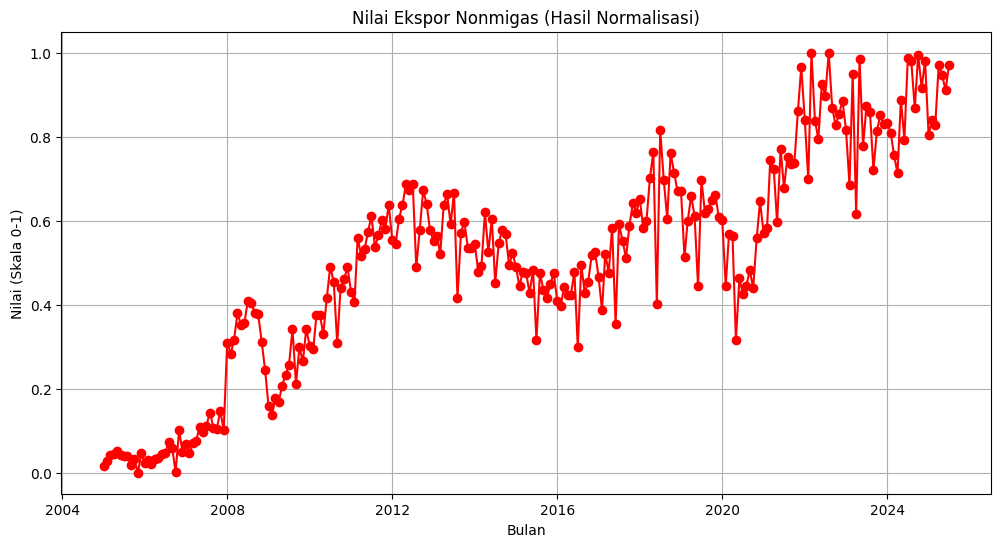

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(df['Bulan'], X_scaled, color="red", marker="o")
plt.title("Nilai Ekspor Nonmigas (Hasil Normalisasi)")
plt.xlabel("Bulan")
plt.ylabel("Nilai (Skala 0-1)")
plt.grid(True)
plt.show()

In [ ]:
# asumsinya 'Bulan' ada di df, 'Nilai Ekspor Nonmigas' ada di output_features
tabel_hasil = pd.DataFrame({
    'Bulan': df['Bulan'],
    'Nilai Ekspor Nonmigas': y.flatten(),
    'Normalisasi': y_scaled.flatten()
})

print(tabel_hasil.head(10))

# Pastikan sudah import pandas
import pandas as pd

# Simpan tabel_hasil ke file Excel
tabel_hasil.to_excel('tabel_hasil.xlsx', index=False)

print("Tabel berhasil disimpan sebagai 'tabel_hasil.xlsx'")

       Bulan  Nilai Ekspor Nonmigas  Normalisasi
0 2005-01-01                 3062.4     0.014835
1 2005-02-01                 3261.9     0.027559
2 2005-03-01                 3502.1     0.042878
3 2005-04-01                 3534.1     0.044919
4 2005-05-01                 3643.7     0.051909
5 2005-06-01                 3508.9     0.043312
6 2005-07-01                 3463.2     0.040397
7 2005-08-01                 3447.5     0.039396
8 2005-09-01                 3113.5     0.018094
9 2005-10-01                 3327.9     0.031768
Tabel berhasil disimpan sebagai 'tabel_hasil.xlsx'


## Splitting Data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.3, shuffle=False)

### tuning timesteps

In [ ]:
timesteps = 3 # menggunakan data 3/6/12 bulan sebelumnya menjadi input LSTM (3)
n_features_input = len(input_features)
n_features_output = len(output_features)

In [ ]:
def create_sequences(X,y,time_steps):
  X_seq, y_seq = [], []

  for i in range(len(X)-time_steps):
    X_seq.append(X[i:i+time_steps])
    y_seq.append(y[i+time_steps])

  return np.array(X_seq), np.array(y_seq)

In [ ]:
X_train_seq, y_train_seq = create_sequences(X_train, y_train, timesteps)
X_test_seq, y_test_seq = create_sequences(X_test, y_test, timesteps)

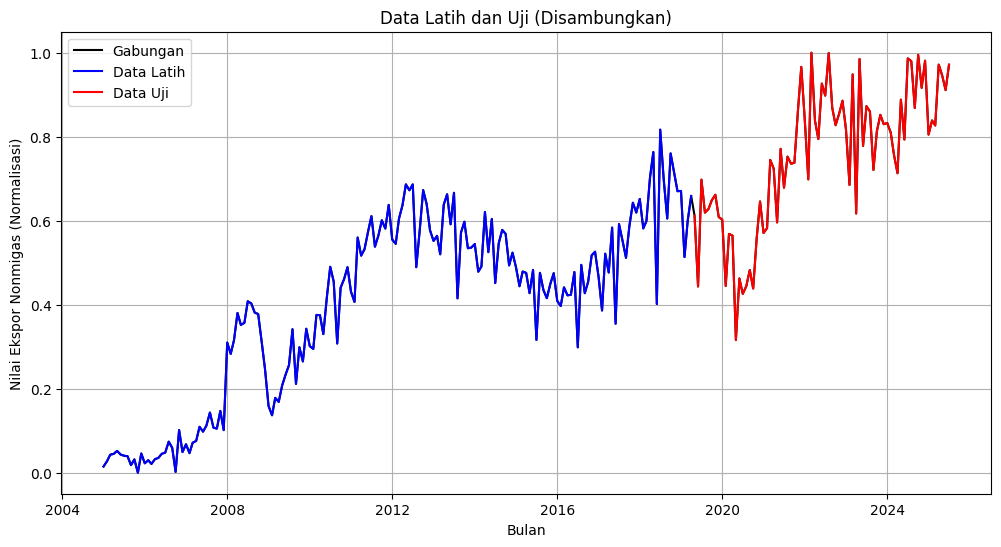

In [ ]:
# Gabungkan data train dan test untuk diurutkan lagi
import pandas as pd

train_df = pd.DataFrame({
    "Bulan": df['Bulan'][:len(y_train)],
    "Nilai": y_train.flatten(),
    "Jenis": "Latih"
})

test_df = pd.DataFrame({
    "Bulan": df['Bulan'][len(y_train):len(y_train)+len(y_test)],
    "Nilai": y_test.flatten(),
    "Jenis": "Uji"
})

# Gabung & urutkan berdasarkan Bulan
combined = pd.concat([train_df, test_df]).sort_values("Bulan")

# Plot garis nyambung
plt.figure(figsize=(12,6))
plt.plot(combined["Bulan"], combined["Nilai"], color="black", label="Gabungan")

# Highlight segmen latih & uji
plt.plot(train_df["Bulan"], train_df["Nilai"], color="blue", label="Data Latih")
plt.plot(test_df["Bulan"], test_df["Nilai"], color="red", label="Data Uji")

plt.title("Data Latih dan Uji (Disambungkan)")
plt.xlabel("Bulan")
plt.ylabel("Nilai Ekspor Nonmigas (Normalisasi)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# misal dataframe asli bernama df dan ada kolom 'bulan'
print("Periode keseluruhan:", df['Bulan'].min(), "sampai", df['Bulan'].max())

# hitung index split
n_train = int(len(df) * 0.7)

# periode latih dan uji
periode_train = (df['Bulan'].iloc[0], df['Bulan'].iloc[n_train-1])
periode_test  = (df['Bulan'].iloc[n_train], df['Bulan'].iloc[-1])

print("Periode data latih:", periode_train[0], "sampai", periode_train[1])
print("Periode data uji:", periode_test[0], "sampai", periode_test[1])

Periode keseluruhan: 2005-01-01 00:00:00 sampai 2025-07-01 00:00:00
Periode data latih: 2005-01-01 00:00:00 sampai 2019-04-01 00:00:00
Periode data uji: 2019-05-01 00:00:00 sampai 2025-07-01 00:00:00


## Model

### tuning unites dan banyak layer

### tuning epochs

In [ ]:
model = Sequential() #30/50/60/100/150/200/32 (32)
model.add(LSTM(32, return_sequences=True, input_shape=(timesteps, n_features_input)))
from tensorflow.keras.layers import Dropout
model.add(Dropout(0.2))
model.add(LSTM(32))
model.add(Dropout(0.2))
model.add(Dense(1))

optimizer = Adam(learning_rate=0.001) # contoh learning rate 0.0005/0.001/0.01 (0.01)
model.compile(optimizer=optimizer, loss='mae')

early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

hist = model.fit(X_train_seq, y_train_seq, epochs=100, batch_size=16, callbacks=[early_stop], verbose=1) # epochs =jumlah iterasi atau berapa kali pelatihan dilakukan, batch_size 32/64/128 (64)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.3858
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2759 
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1586 
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1220 
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1036 
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0952 
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0896
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0842 
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0872
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0628 
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0707 
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0726 
Epoch 13/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0645 
Epoch 14/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0692
Epoch 15/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0

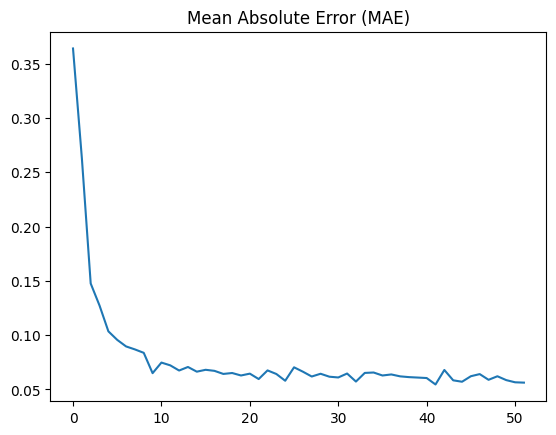

In [ ]:
model_history = hist.history
loss = model_history['loss']

plt.figure()
plt.plot(loss, label = 'MAE')
plt.title('Mean Absolute Error (MAE)')
plt.show()

## Prediksi Data Test

In [ ]:
predictions = model.predict(X_test_seq)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step


In [ ]:
predictions = scaler.inverse_transform(predictions)
y_test_asli = scaler.inverse_transform(y_test_seq)

## Prediksi Data Training

In [ ]:
predictions_train = model.predict(X_train_seq)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


In [ ]:
predictions_train = scaler.inverse_transform(predictions_train)
y_train_asli = scaler.inverse_transform(y_train_seq)

## MAPE Testing

In [ ]:
mae = np.mean(np.abs(predictions - y_test_asli), axis = 0)
print("Mean Absolute Error (MAE):", mae)

Mean Absolute Error (MAE): [1180.31765408]


In [ ]:
treshold_mae = df['Nilai Ekspor Nonmigas'].max()-df['Nilai Ekspor Nonmigas'].min()
print("Treshold MAE:", treshold_mae)

Treshold MAE: 15679.3


In [ ]:
mape = np.mean((np.abs((predictions - y_test_asli)/y_test_asli))*100, axis = 0)
print("Mean Absolute Percentage Error (MAPE):", mape)

Mean Absolute Percentage Error (MAPE): [8.18291419]


## MAPE Training

In [ ]:
mae_train = np.mean(np.abs(predictions_train - y_train_asli), axis = 0)
print("Mean Absolute Error (MAE):", mae_train)

Mean Absolute Error (MAE): [796.59347899]


In [ ]:
treshold_mae_train = df['Nilai Ekspor Nonmigas'].max()-df['Nilai Ekspor Nonmigas'].min()
print("Treshold MAE:", treshold_mae_train)

Treshold MAE: 15679.3


In [ ]:
mape_train = np.mean((np.abs((predictions_train - y_train_asli)/y_train_asli))*100, axis = 0)
print("Mean Absolute Percentage Error (MAPE):", mape_train)

Mean Absolute Percentage Error (MAPE): [9.46285325]


## Visualisasi

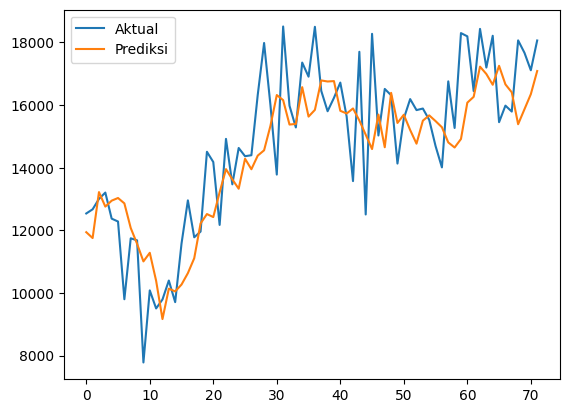

In [ ]:
plt.figure()
plt.plot(y_test_asli[:,0], label="Aktual")
plt.plot(predictions[:,0], label="Prediksi")
plt.legend()
plt.show()

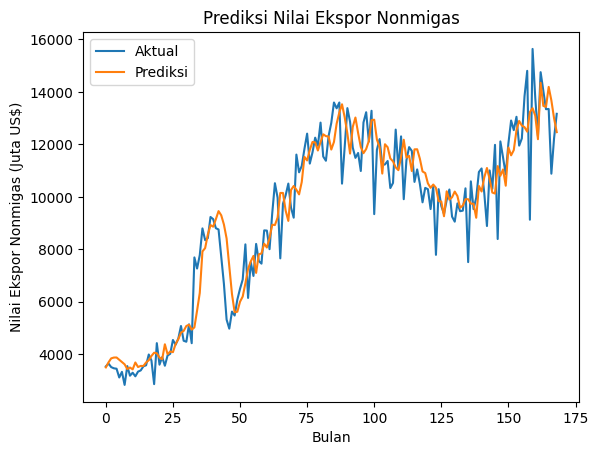

In [ ]:
plt.figure()
plt.plot(y_train_asli[:,0], label="Aktual")
plt.plot(predictions_train[:,0], label="Prediksi")
plt.title("Prediksi Nilai Ekspor Nonmigas")
plt.xlabel("Bulan")
plt.ylabel("Nilai Ekspor Nonmigas (Juta US$)")
plt.legend()
plt.show()

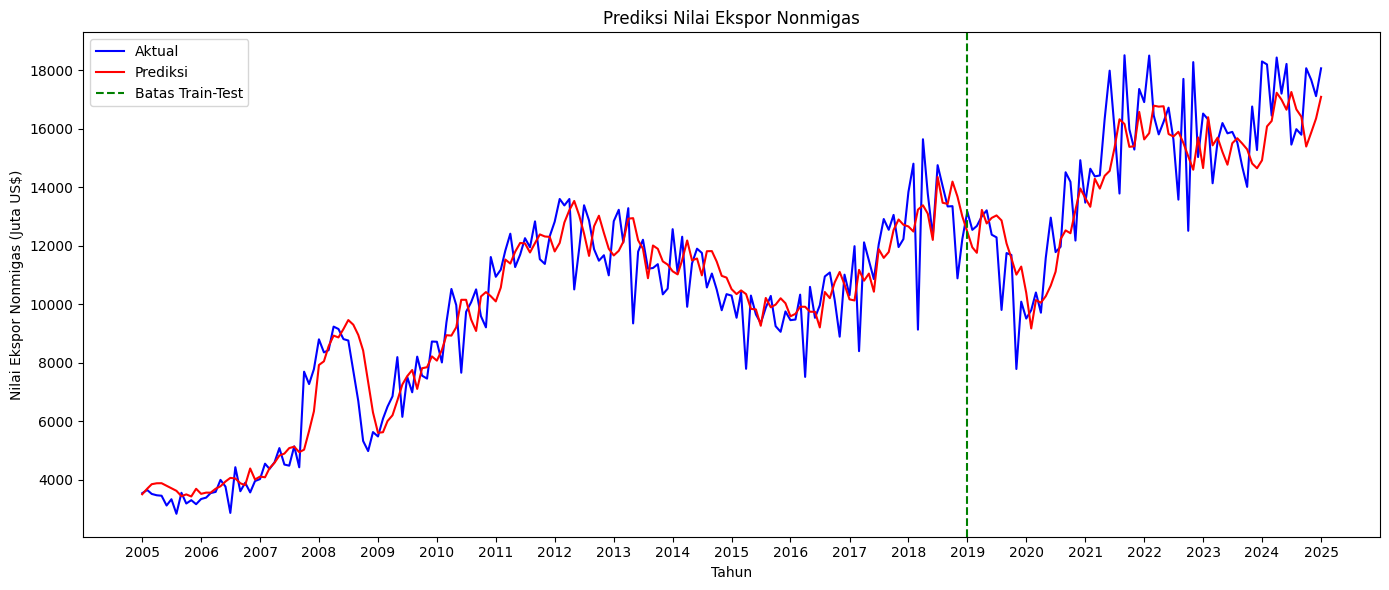

In [ ]:
# Ambil kolom pertama (kalau array 2D)
y_train_vals = y_train_asli[:,0]
y_test_vals = y_test_asli[:,0]
pred_train_vals = predictions_train[:,0]
pred_test_vals = predictions[:,0]

# Gabungkan aktual dan prediksi
y_all = np.concatenate([y_train_vals, y_test_vals])
pred_all = np.concatenate([pred_train_vals, pred_test_vals])

# Buat index bulan mulai dari Jan 2015
tanggal_index = pd.date_range(start="2005-01", periods=len(y_all), freq="MS")

plt.figure(figsize=(14,6))
plt.plot(tanggal_index, y_all, label="Aktual", color="blue")
plt.plot(tanggal_index, pred_all, label="Prediksi", color="red")

# Garis vertikal batas train-test
plt.axvline(x=tanggal_index[len(y_train_vals)-1], color="green", linestyle="--", label="Batas Train-Test")

# Format sumbu X -> tahun saja
tahun_ticks = pd.date_range(start="2005-01", end=tanggal_index[-1], freq="YS")  # tiap awal tahun
plt.xticks(tahun_ticks, tahun_ticks.strftime("%Y"))

plt.title("Prediksi Nilai Ekspor Nonmigas")
plt.xlabel("Tahun")
plt.ylabel("Nilai Ekspor Nonmigas (Juta US$)")
plt.legend()
plt.tight_layout()
plt.show()

## Prediksi 6 Bulan Kedepan

      Bulan  Prediksi Nilai Ekspor Nonmigas (Juta US$)
0   2025-08                               16907.914062
1   2025-09                               16781.328125
2   2025-10                               16842.470703
3   2025-11                               16351.713867
4   2025-12                               16250.192383
5   2026-01                               16129.379883
6   2026-02                               15883.331055
7   2026-03                               15774.549805
8   2026-04                               15641.938477
9   2026-05                               15490.862305
10  2026-06                               15387.563477
11  2026-07                               15275.426758
12  2026-08                               15167.162109
13  2026-09                               15076.863281
14  2026-10                               14986.169922
15  2026-11                               14901.874023
16  2026-12                               14825.830078


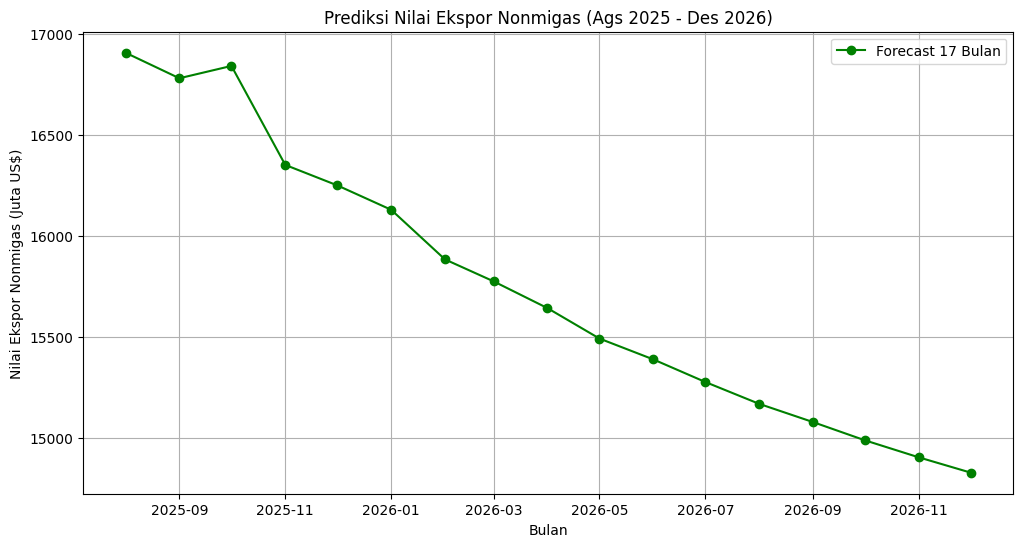

In [ ]:
# -------- Prediksi 17 Bulan ke Depan -------- #

n_future = 17          # jumlah bulan prediksi ke depan
n_steps = timesteps    # jumlah timesteps yang dipakai LSTM

# Ambil sequence terakhir dari data training+testing
last_sequence = X_scaled[-n_steps:]
current_input = last_sequence.reshape(1, n_steps, n_features_input)

future_predictions = []

for _ in range(n_future):
    # Prediksi 1 langkah
    pred = model.predict(current_input, verbose=0)
    future_predictions.append(pred[0, 0])

    # Update sequence input untuk prediksi berikutnya
    pred_reshaped = pred.reshape(1, 1, n_features_input)
    current_input = np.concatenate([current_input[:, 1:, :], pred_reshaped], axis=1)

# Kembalikan ke skala asli
future_predictions = scaler.inverse_transform(np.array(future_predictions).reshape(-1, 1))

# Ambil tanggal terakhir dari data asli
last_date = pd.to_datetime(df['Bulan']).iloc[-1]

# Buat index waktu (Agustus 2025 – Desember 2026)
future_index = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=n_future, freq="MS"
)

# Buat tabel hasil prediksi
df_future = pd.DataFrame({
    "Bulan": future_index.strftime("%Y-%m"),
    "Prediksi Nilai Ekspor Nonmigas (Juta US$)": future_predictions.flatten()
})

print(df_future)

# Plot hasil prediksi
plt.figure(figsize=(12,6))
plt.plot(future_index, future_predictions, marker="o", color="green", label="Forecast 17 Bulan")
plt.title("Prediksi Nilai Ekspor Nonmigas (Ags 2025 - Des 2026)")
plt.xlabel("Bulan")
plt.ylabel("Nilai Ekspor Nonmigas (Juta US$)")
plt.legend()
plt.grid(True)
plt.show()

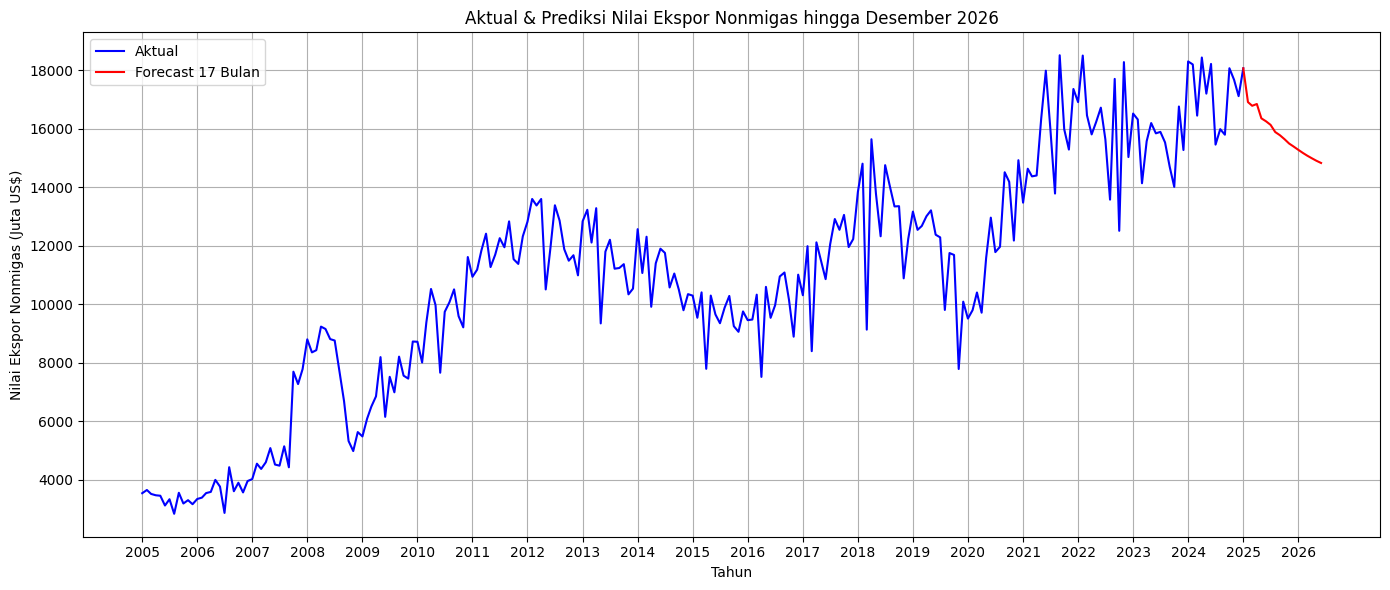

In [ ]:
# -------- Gabungkan Data Aktual + Forecast -------- #

# Buat array gabungan aktual + prediksi
y_full = np.concatenate([y_all, future_predictions.flatten()])

# Buat index gabungan dari awal data sampai akhir forecast
tanggal_full = pd.date_range(start=pd.to_datetime(df['Bulan']).iloc[0],
                             periods=len(y_full), freq="MS")

# Plot
plt.figure(figsize=(14,6))

# Data aktual
plt.plot(tanggal_full[:len(y_all)], y_all, color="blue", label="Aktual")

# Data prediksi masa depan (nyambung langsung dari aktual)
plt.plot(tanggal_full[len(y_all)-1:],
         np.concatenate([[y_all[-1]], future_predictions.flatten()]),
         color="red", label="Forecast 17 Bulan")

# Format sumbu X -> tahun
tahun_ticks = pd.date_range(start="2005-01", end=tanggal_full[-1], freq="YS")
plt.xticks(tahun_ticks, tahun_ticks.strftime("%Y"))

plt.title("Aktual & Prediksi Nilai Ekspor Nonmigas hingga Desember 2026")
plt.xlabel("Tahun")
plt.ylabel("Nilai Ekspor Nonmigas (Juta US$)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
